# Request and update GOOS passports

This notebook demostrates how to request new passports for a platform, and how to use the GOOS API to directly update exisiting passports.

**This assumes you have your datasets on an ERDDAP server and will require some customisation if those datasets are not in OG1 format**

In [1]:
import json
from pathlib import Path
import requests
import xarray as xr
import numpy as np
import datetime
import pandas as pd
import matplotlib.pyplot as plt
from erddapy import ERDDAP

### Authentication

The GOOS API requires authentication, see the [API token guide](https://www.ocean-ops.org/passports/#/tokens)

You can add your auth in a file `secrets.json` in the home directory of this repo, or directly in the cell below

In [2]:
oceanops_auth = {'X-OceanOPS-Metadata-ID': 'nnnn',
 'X-OceanOPS-Metadata-Token': '16-char-secret-token'}

if Path('../secrets.json').exists():
    with open('../secrets.json') as f:
        oceanops_auth = json.load(f)
else:
    print("enter your oceanOPS authentication in the dictionary `oceanops_auth` in this cell")

In [3]:
headers = {
    'Content-Type': 'application/json' ,
    'accept': 'application/json' ,
    **oceanops_auth
}
output_dir = Path('output')
if not output_dir.exists():
    output_dir.mkdir()

# Read in info from GOOS

This uses the output of notebook 01, so go run that first!

In [4]:
wmo_id = 6801674
platform_serial = 'SEA055'
df_oceanops = pd.read_csv(output_dir / f'goos_data_{wmo_id}.csv')
for col in df_oceanops.columns:
    if 'date' in col.lower():
        df_oceanops[col] = pd.to_datetime(df_oceanops[col])

# Update info on WMO passports

Update the deployment and recovery dates of missions and request passports for missions that do not have them. 

1. loop through the ERDDAP table of missions chronologically and make a table of the data we have on each mission

In [5]:
e = ERDDAP(
    server="https://erddap.observations.voiceoftheocean.org/erddap",
    protocol="tabledap",
)
e.response = "csv"
e.dataset_id = "allDatasets"
df_datasets = e.to_pandas()
df_datasets = df_datasets[df_datasets.datasetID.str.contains("_R")] # these are our nrt OG1 datasets
df_ids = df_datasets.datasetID.str.split('_',expand=True)
df_datasets['platform_serial'] = df_ids[0]
df_datasets['mission'] = df_ids[1]
df_platform = df_datasets[df_datasets.platform_serial==platform_serial.lower()]
df_platform = df_platform.rename({'minTime (UTC)': 'deployment_date', 'maxTime (UTC)': 'recovery_date'}, axis=1)
subset_vars =['datasetID', 'title',  'summary', 'platform_serial', 'mission', 'deployment_date', 'recovery_date']
df_platform['deployment_date'] = pd.to_datetime(df_platform.deployment_date)
df_platform['recovery_date'] = pd.to_datetime(df_platform.recovery_date)
df_platform = df_platform[subset_vars]
df_platform = df_platform.sort_values('deployment_date')
df_platform['gtsId'] = wmo_id
print(f"Found data for {len(df_platform)} deployments on ERDDAP")
df_platform.head()

Found data for 33 deployments on ERDDAP


,datasetID,title,summary,platform_serial,mission,deployment_date,recovery_date,gtsId
664,sea055_20201031T0902_R,sea055_20201031T0902_R M16 Kaprifol,Altitude set to 5m for most of the mission but...,sea055,20201031T0902,2020-10-31 09:03:00+00:00,2020-11-19 10:00:30+00:00,6801674
666,sea055_20210305T0812_R,sea055_20210305T0812_R M18 Kaprifol,Altitude set to 5m for most of the mission and...,sea055,20210305T0812,2021-03-05 08:13:31+00:00,2021-03-25 11:39:00+00:00,6801674
668,sea055_20210326T0937_R,sea055_20210326T0937_R M19 Kaprifol,Altitude set to 5m for the entire mission dura...,sea055,20210326T0937,2021-03-26 09:38:30+00:00,2021-04-14 04:46:00+00:00,6801674
670,sea055_20210414T1704_R,sea055_20210414T1704_R M20 Kaprifol,Altitude set to 5m for the entire mission dura...,sea055,20210414T1704,2021-04-14 17:13:03+00:00,2021-05-02 16:11:30+00:00,6801674
672,sea055_20210503T0601_R,sea055_20210503T0601_R M21 Kaprifol,Altitude set to 5m for the entire mission dura...,sea055,20210503T0601,2021-05-03 06:19:00+00:00,2021-05-21 14:57:00+00:00,6801674


2. Use the deployment date to match missions in our table to existing passports

In [6]:
df_platform['wigosId'] = ''
matches = 0
for i, row in df_platform.iterrows():
    deploy_diff = df_oceanops.deployment_date - row.deployment_date
    time_match = np.abs(deploy_diff) < np.timedelta64(3, 'D')
    if time_match.any():
        matching_passports = df_oceanops[time_match]
        if len(matching_passports == 1):
            matches += 1
            df_platform.loc[i, 'wigosId'] = matching_passports['wigosId'].values[0]
        else:
            print("Error! More than one match detected")
print(f'Matched {matches} datasets')

Matched 33 datasets


4. Check for datasets on ERDDAP with no corresponding wigos ID

In [7]:
datasets_no_wigos = df_platform[df_platform['wigosId']=='']
if not datasets_no_wigos.empty:
    print(f"Failed to find wigos IDs for these datasetson  ERDDAP:")
datasets_no_wigos[['datasetID',  'deployment_date', 'recovery_date']]

,datasetID,deployment_date,recovery_date


5. Check for datasets on oceanOPS with no corresponding dataset on our side

In [8]:
unmatched_wigos = set(df_oceanops.index).difference(set(df_platform.wigosId))
if unmatched_wigos:
    print("No corresponding dataset found on ERDDAP for assigned wigos passports:")
df_oceanops[df_oceanops.wigosId.isin(unmatched_wigos)][['wigosId', 'deployment_date', 'retrieval_startDate']]

No corresponding dataset found on ERDDAP for assigned wigos passports:


,wigosId,deployment_date,retrieval_startDate


3. Merge the OceanOPS table and our table to compare information

In [9]:
dfa = df_platform[['datasetID', 'mission', 'title', 'deployment_date', 'recovery_date', 'wigosId', 'gtsId', 'platform_serial']]

dfb =df_oceanops[['passport_num', 'wigosId', 'name','deployment_date', 'identification_internalId', 'retrieval_startDate','retrieval_endDate', 'retrieval_endingCause' ]]
df = pd.merge(dfa, dfb, left_on='wigosId', right_on='wigosId', suffixes=('_voto', '_ops'), how='left')
df[df.wigosId!= ''].head()

,datasetID,mission,title,deployment_date_voto,recovery_date,wigosId,gtsId,platform_serial,passport_num,name,deployment_date_ops,identification_internalId,retrieval_startDate,retrieval_endDate,retrieval_endingCause
0,sea055_20201031T0902_R,20201031T0902,sea055_20201031T0902_R M16 Kaprifol,2020-10-31 09:03:00+00:00,2020-11-19 10:00:30+00:00,0-22000-0-6801674,6801674,sea055,0,Kaprifol,2020-10-31 09:03:00+00:00,Kaprifol55-20201031T0902,2020-11-19 10:00:30+00:00,2020-11-19 10:00:30+00:00,"{'code': 'voluntary-recovery-of-the-platform',..."
1,sea055_20210305T0812_R,20210305T0812,sea055_20210305T0812_R M18 Kaprifol,2021-03-05 08:13:31+00:00,2021-03-25 11:39:00+00:00,0-22000-1-6801674,6801674,sea055,1,Kaprifol,2021-03-05 08:13:31+00:00,Kaprifol55-20210305T0813,2021-03-25 11:39:00+00:00,2021-03-25 11:39:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',..."
2,sea055_20210326T0937_R,20210326T0937,sea055_20210326T0937_R M19 Kaprifol,2021-03-26 09:38:30+00:00,2021-04-14 04:46:00+00:00,0-22000-2-6801674,6801674,sea055,2,Kaprifol,2021-03-26 09:38:30+00:00,Kaprifol55-20210326T0938,2021-04-14 04:46:00+00:00,2021-04-14 04:46:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',..."
3,sea055_20210414T1704_R,20210414T1704,sea055_20210414T1704_R M20 Kaprifol,2021-04-14 17:13:03+00:00,2021-05-02 16:11:30+00:00,0-22000-3-6801674,6801674,sea055,3,Kaprifol,2021-04-14 17:13:03+00:00,Kaprifol55-20210414T1713,2021-05-02 16:11:30+00:00,2021-05-02 16:11:30+00:00,"{'code': 'voluntary-recovery-of-the-platform',..."
4,sea055_20210503T0601_R,20210503T0601,sea055_20210503T0601_R M21 Kaprifol,2021-05-03 06:19:00+00:00,2021-05-21 14:57:00+00:00,0-22000-4-6801674,6801674,sea055,4,Kaprifol,2021-05-03 06:19:00+00:00,Kaprifol55-20210503T0609,2021-05-21 14:57:00+00:00,2021-05-21 14:57:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',..."


Plot temporal extents of OceanOPS and VOTO deployments

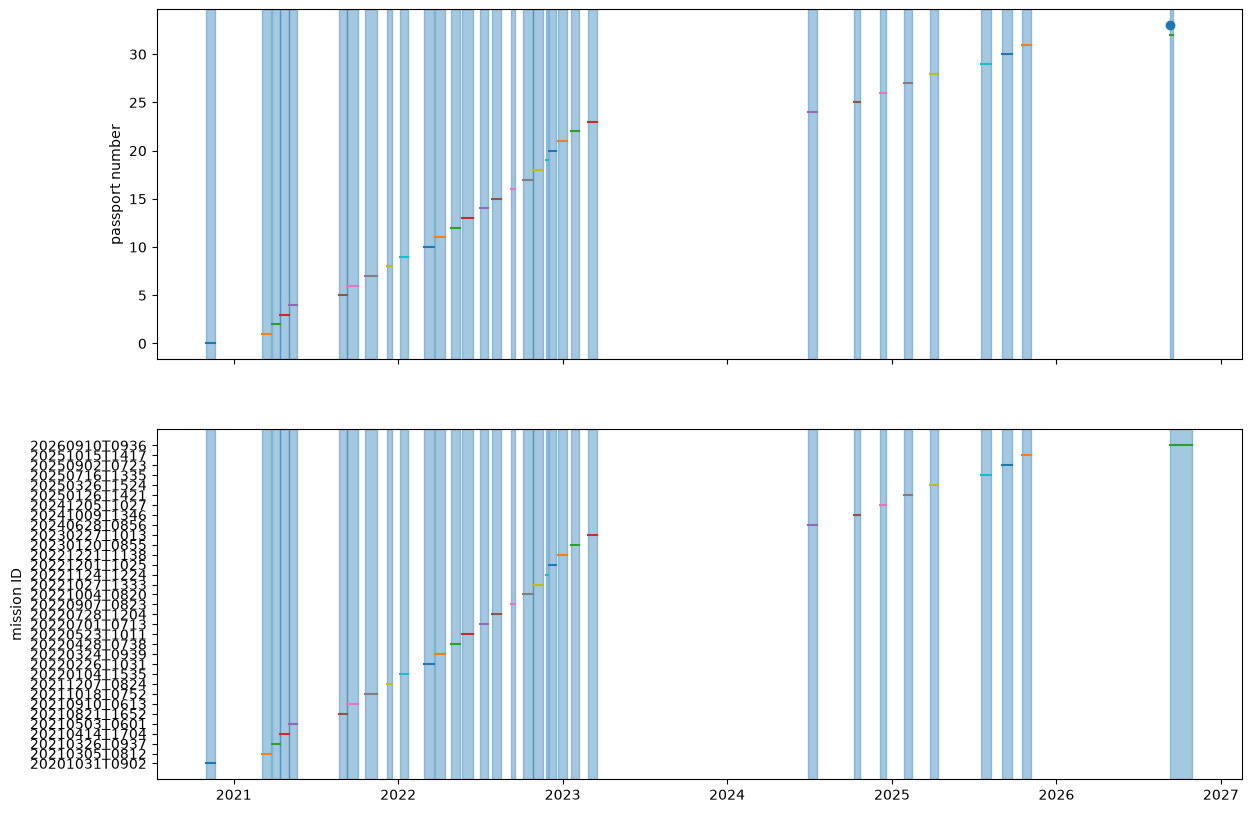

In [10]:
fig, ax = plt.subplots(2, 1, sharex='col', figsize=(14, 10))
ax = ax.ravel()
for i, row in df_oceanops.iterrows():
    if not pd.isnull(row.deployment_date) and not pd.isnull(row.retrieval_startDate):
        color='C1' if row.wigosId in unmatched_wigos else 'C0'
        ax[0].axvspan(row.deployment_date, row.retrieval_startDate, alpha=0.4, color=color)

        ax[0].plot((row.deployment_date, row.retrieval_startDate), (row.passport_num, row.passport_num))
        continue
    if not pd.isnull(row.deployment_date):
        ax[0].scatter((row.deployment_date, ), (row.passport_num))
        continue
    ax[0].scatter((row.retrieval_startDate, ), (row.passport_num), marker='s')
ax[0].set(ylabel='passport number');

for i, row in df_platform.iterrows():
    color='C1' if row.wigosId == '' else 'C0'

    ax[1].axvspan(row.deployment_date, row.recovery_date, alpha=0.4, color=color)

    ax[1].plot((row.deployment_date, row.recovery_date), (row.mission, row.mission))
ax[1].set(ylabel='mission ID');

4. Go back over the table, updating recovery dates for missions that do not have them

In [11]:
for i, row in df.iterrows():
    if row.wigosId:
        if pd.isnull(row.retrieval_endingCause):
            json_data =  {
            "retrieval": {
                "endingCause": {
          "code": "voluntary-recovery-of-the-platform"
                        }
                    }
            }

            url = f'https://www.ocean-ops.org/api/data/platforms/{row.wigosId}'
            response = requests.patch(url, headers=headers, json=json_data)
            resp = response.json()
            print(resp)

        if not pd.isnull(row.retrieval_startDate) and not pd.isnull(row.retrieval_endDate):
            continue
        json_data =   {
            "retrieval": {
                "startDate": row.recovery_date.isoformat().replace('+00:00', 'Z'),
                "endDate": row.recovery_date.isoformat().replace('+00:00', 'Z')}
                      }
        url = f'https://www.ocean-ops.org/api/data/platforms/{row.wigosId}'
        response = requests.patch(url, headers=headers, json=json_data)
        resp_json = response.json()
        print(resp_json)


### Request passport IDs for missions that do not have them

**Note** the API will return a 200 even if it rejects your request to mint a new Passport ID in some circumstances, check the returned json for a 'success' message to see that the new passport has been minted

In [12]:
for i, row in df.iterrows():
    if row.wigosId:
        continue
    url = 'https://www.ocean-ops.org/api/data/platforms/getid'

    json_data =   [{
        "program": "VOTO: Ocean Knowledge glider program",
        "model": "SeaExplorer X2",
        "startDate": row.deployment_date_voto.isoformat().replace('+00:00', ''),
        "endDate": row.recovery_date.isoformat().replace('+00:00', ''),
        "gtsId": row.gtsId,
        "closeCurrentMission": "true"
      }]

    response = requests.post(url, headers=headers, json=json_data)
    print("Status", response.status_code)
    resp_json = response.json()[0]
    if not resp_json['success']:
        print("ERROR request denied")
        print(resp_json)
        continue
    print(f'SUCCESS. minted new wigos passport {response.json()[0]['wigosRef']}')

**re-run noteboook 01 to rebuild your table of info that GOOS has for this platform**